# Treinamento e comparação dos modelos

## Objetivo

Treinar e comparar modelos de Machine Learning
para classificação do risco de baixo peso ao nascer,
utilizando a base SINASC de 2024.

## Modelos a serem avaliados

- DummyClassifier (baseline).
- Regressão Logística.
- Random Forest.

## Estratégia de avaliação

- Investigação dos registros duplicados.
- Separação estratificada de treinamento e teste.
- Validação cruzada estratificada com 5 folds.
- Avaliação do desbalanceamento das classes.
- Recall da classe positiva como métrica prioritária.
- Precision, F2, PR-AUC e ROC-AUC como métricas complementares.
- Conjunto de teste reservado para avaliação final.

In [1]:
import pandas as pd
import numpy as np
import sys

from pathlib import Path

# Identificar a raiz do repositório
raiz = Path.cwd()

while not (raiz / ".git").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("Repositório não localizado.")

    raiz = raiz.parent

sys.path.insert(0, str(raiz / "ml" / "src"))

from data_preparation import (
    carregar_dados,
    criar_variavel_alvo,
    separar_atributos_alvo,
    verificar_vazamento
)

from preprocessing import criar_pipeline

# Carregar os dados originais
df = carregar_dados()

print("Dimensões:", df.shape)
print("Registros duplicados:", df.duplicated().sum())

Dimensões: (120786, 37)
Registros duplicados: 5


## Investigação dos registros duplicados

Verificação dos registros integralmente duplicados
na base original, buscando evitar que cópias de um
mesmo registro estejam presentes simultaneamente
nos conjuntos de treinamento e teste.

In [2]:
# Identificar todos os registros envolvidos em duplicações
duplicados = df[df.duplicated(keep=False)]

# Identificar a quantidade de grupos distintos
grupos_duplicados = duplicados.drop_duplicates()

print("Total de registros:", len(df))

print("Duplicações excedentes:",
      df.duplicated().sum())

print("Registros envolvidos em duplicações:",
      len(duplicados))

print("Grupos de registros duplicados:",
      len(grupos_duplicados))

# Verificar a quantidade de ocorrências por grupo
print("\nOcorrências por grupo:")

display(
    duplicados.value_counts(dropna=False)
    .value_counts()
    .sort_index()
    .rename_axis("Ocorrências")
    .rename("Quantidade de grupos")
    .to_frame()
)

Total de registros: 120786
Duplicações excedentes: 5
Registros envolvidos em duplicações: 10
Grupos de registros duplicados: 5

Ocorrências por grupo:


,Quantidade de grupos
Ocorrências,
2,5


## Tratamento dos registros duplicados

Foram identificados cinco grupos de registros integralmente idênticos, cada um com duas ocorrências. Como medida preventiva contra a contaminação entre treinamento e teste, vamos manter apenas uma ocorrência de cada grupo.

A remoção considera exclusivamente duplicações exatas nas 37 colunas da base original.


In [3]:
# Remover somente duplicações integrais
df_sem_duplicados = df.drop_duplicates().copy()

print("Registros antes:",
      len(df))

print("Registros depois:",
      len(df_sem_duplicados))

print("Registros removidos:",
      len(df) - len(df_sem_duplicados))

print("Duplicações restantes:",
      df_sem_duplicados.duplicated().sum())

# Validar a remoção
assert df_sem_duplicados.duplicated().sum() == 0

print("\nTratamento de duplicações: OK")

Registros antes: 120786
Registros depois: 120781
Registros removidos: 5
Duplicações restantes: 0

Tratamento de duplicações: OK


In [ ]:
## Preparação da base para modelagem

Após o tratamento das duplicações, serão utilizadas
as funções implementadas no módulo data_preparation.py.

Nesta etapa serão realizadas:

- Validação dos valores de peso ao nascer.
- Criação da variável-alvo baixo_peso.
- Separação dos atributos preditores e da variável-alvo.
- Verificação de possíveis atributos com vazamento.
- Análise da distribuição das classes.

In [4]:
# Criar a variável-alvo na base sem duplicações
dados = criar_variavel_alvo(df_sem_duplicados)

# Separar atributos preditores e variável-alvo
X, y = separar_atributos_alvo(dados)

# Verificar possíveis atributos com vazamento
verificar_vazamento(X)

print("Registros após validação do peso:", len(dados))

print("\nDimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

print("\nDistribuição das classes:")

distribuicao = pd.DataFrame({
    "Quantidade": y.value_counts().sort_index(),
    "Percentual (%)": (
        y.value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(distribuicao)

print("\nAtributos preditores:")
print(X.columns.tolist())

Verificação de vazamento: OK
Registros após validação do peso: 120780

Dimensões de X: (120780, 10)
Dimensões de y: (120780,)

Distribuição das classes:


,Quantidade,Percentual (%)
baixo_peso,,
0,108311,89.68
1,12469,10.32



Atributos preditores:
['FxEtPartur', 'ESTCIVMAE', 'ESCMAE2010', 'GRAVIDEZ', 'QTDGESTANT', 'QTDPARTNOR', 'QTDPARTCES', 'QTDFILVIVO', 'QTDFILMORT', 'MESPRENAT']


## Divisão dos conjuntos de treinamento e teste

A base preparada será dividida em 80% para treinamento
e 20% para teste. Será utilizada uma divisão estratificada para preservar a proporção das classes nos dois conjuntos.

O random_state será definido como 42 para garantir a reprodutibilidade dos experimentos. O conjunto de treinamento será utilizado na validação cruzada e na seleção dos modelos.

O conjunto de teste será reservado exclusivamente
para a avaliação final.

In [5]:
from sklearn.model_selection import train_test_split

# Divisão estratificada dos dados
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensões de X_treino:", X_treino.shape)
print("Dimensões de X_teste:", X_teste.shape)

print("Dimensões de y_treino:", y_treino.shape)
print("Dimensões de y_teste:", y_teste.shape)

# Comparar a distribuição das classes
distribuicao_split = pd.DataFrame({
    "Base completa (%)": y.value_counts(normalize=True) * 100,
    "Treinamento (%)": y_treino.value_counts(normalize=True) * 100,
    "Teste (%)": y_teste.value_counts(normalize=True) * 100
})

display(distribuicao_split.sort_index().round(4))

# Verificar se os conjuntos possuem registros em comum
intersecao = X_treino.index.intersection(X_teste.index)

assert len(intersecao) == 0
assert len(X_treino) + len(X_teste) == len(X)

print("\nRegistros em comum pelos índices:", len(intersecao))
print("Divisão dos dados: OK")

Dimensões de X_treino: (96624, 10)
Dimensões de X_teste: (24156, 10)
Dimensões de y_treino: (96624,)
Dimensões de y_teste: (24156,)


,Base completa (%),Treinamento (%),Teste (%)
baixo_peso,,,
0,89.6763,89.6765,89.6754
1,10.3237,10.3235,10.3246



Registros em comum pelos índices: 0
Divisão dos dados: OK


## Configuração da validação cruzada e das métricas

Será utilizada a validação cruzada estratificada com 5 folds, principalmente no conjunto de treinamento. A métrica prioritária será o Recall da classe positiva, considerando a importância de reduzir falsos negativos.

As métricas complementares serão:

- Precision.
- F1-score.
- F2-score.
- PR-AUC (Average Precision).
- ROC-AUC.
- Acurácia.

A acurácia não será utilizada isoladamente para
selecionar o melhor modelo devido ao desbalanceamento
das classes.

In [7]:
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    make_scorer,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score
)

# Configurar validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configurar métricas de avaliação
metricas = {
    "accuracy": "accuracy",

    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),

    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),

    "f2": make_scorer(
        fbeta_score,
        beta=2,
        zero_division=0
    ),

    "pr_auc": "average_precision",

    "roc_auc": "roc_auc"
}

print("Validação cruzada configurada.")
print("Quantidade de folds:", cv.get_n_splits())

print("\nMétricas configuradas:")

for metrica in metricas:
    print("-", metrica)

Validação cruzada configurada.
Quantidade de folds: 5

Métricas configuradas:
- accuracy
- recall
- precision
- f1
- f2
- pr_auc
- roc_auc


## Modelo 1 — DummyClassifier (Baseline)

O DummyClassifier será utilizado como modelo de
referência para a comparação dos classificadores.

A estratégia most_frequent prevê sempre a classe
mais frequente do conjunto de treinamento. A avaliação será realizada utilizando validação cruzada estratificada com 5 folds e o pipeline completo de pré-processamento.

Serão calculadas a média e o desvio-padrão das
métricas de avaliação. O Dummy vai nos permitir verificar se os modelos mais elaborados realmente conseguem aprender padrões relevantes nos dados.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

# Criar o modelo de referência
modelo_dummy = DummyClassifier(
    strategy="most_frequent"
)

# Construir o pipeline completo
pipeline_dummy = criar_pipeline(modelo_dummy)

# Executar a validação cruzada
resultados_dummy = cross_validate(
    pipeline_dummy,
    X_treino,
    y_treino,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

print("Validação cruzada do DummyClassifier concluída.")

Validação cruzada do DummyClassifier concluída.


In [ ]:
# Armazenar os resultados das métricas
resumo_dummy = pd.DataFrame({
    "Métrica": list(metricas.keys()),

    "Média": [
        resultados_dummy[f"test_{metrica}"].mean()
        for metrica in metricas
    ],

    "Desvio-padrão": [
        resultados_dummy[f"test_{metrica}"].std()
        for metrica in metricas
    ]
})

display(resumo_dummy.round(4))



,Métrica,Média,Desvio-padrão
0,accuracy,0.8968,0.0
1,recall,0.0000,0.0
2,precision,0.0000,0.0
3,f1,0.0000,0.0
4,f2,0.0000,0.0
5,pr_auc,0.1032,0.0
6,roc_auc,0.5000,0.0



Tempo médio de treinamento por fold: 0.476 segundos


O resultado mostra que mesmo com 89,68% de acurácia, o modelo não identifica nenhum caso de baixo peso.

## Modelo 2 — Regressão Logística

A Regressão Logística será utilizada como modelo
de classificação supervisionada, permitindo avaliar
a relação entre os atributos preditores e a
ocorrência de baixo peso ao nascer.

Inicialmente, o modelo será treinado sem
balanceamento de classes. Serão utilizadas as mesmas condições de avaliação do modelo de referência:

- Pipeline completo de pré-processamento.
- Validação cruzada estratificada com 5 folds.
- Mesmas métricas de avaliação.
- Random state igual a 42.

In [10]:
from sklearn.linear_model import LogisticRegression

# Criar o modelo de Regressão Logística
modelo_logistica = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight=None,
    solver="lbfgs"
)

# Construir o pipeline completo
pipeline_logistica = criar_pipeline(
    modelo_logistica
)

# Executar a validação cruzada
resultados_logistica = cross_validate(
    pipeline_logistica,
    X_treino,
    y_treino,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

print("Validação cruzada da Regressão Logística concluída.")

Validação cruzada da Regressão Logística concluída.


In [11]:
# Consolidar os resultados da Regressão Logística
resumo_logistica = pd.DataFrame({
    "Métrica": list(metricas.keys()),

    "Média": [
        resultados_logistica[f"test_{metrica}"].mean()
        for metrica in metricas
    ],

    "Desvio-padrão": [
        resultados_logistica[f"test_{metrica}"].std()
        for metrica in metricas
    ]
})

display(resumo_logistica.round(4))

print(
    "\nTempo médio de treinamento por fold:",
    round(resultados_logistica["fit_time"].mean(), 4),
    "segundos"
)

,Métrica,Média,Desvio-padrão
0,accuracy,0.9042,0.0009
1,recall,0.1661,0.0045
2,precision,0.6396,0.0169
3,f1,0.2637,0.0068
4,f2,0.1950,0.0052
5,pr_auc,0.2694,0.0059
6,roc_auc,0.6383,0.0075



Tempo médio de treinamento por fold: 1.1135 segundos


A Regressão Logística apresentou uma evolução em relação ao DummyClassifier, demonstrando capacidade de aprender padrões associados ao baixo peso ao nascer. Entretanto, ainda precisamos melhorar o Recall.

## Modelo 3 — Random Forest

O Random Forest será utilizado como modelo de
classificação baseado em um conjunto de árvores
de decisão. O objetivo é avaliar sua capacidade de identificar
relações não lineares e interações entre os atributos preditores.

Inicialmente, o modelo será treinado sem
balanceamento de classes.

Serão mantidas as mesmas condições de avaliação:

- Pipeline completo de pré-processamento.
- Validação cruzada estratificada com 5 folds.
- Mesmas métricas de avaliação.
- Random state igual a 42.

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Criar o modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Construir o pipeline completo
pipeline_rf = criar_pipeline(modelo_rf)

# Executar a validação cruzada
resultados_rf = cross_validate(
    pipeline_rf,
    X_treino,
    y_treino,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

print("Validação cruzada do Random Forest concluída.")

Validação cruzada do Random Forest concluída.


In [13]:
# Consolidar os resultados do Random Forest
resumo_rf = pd.DataFrame({
    "Métrica": list(metricas.keys()),

    "Média": [
        resultados_rf[f"test_{metrica}"].mean()
        for metrica in metricas
    ],

    "Desvio-padrão": [
        resultados_rf[f"test_{metrica}"].std()
        for metrica in metricas
    ]
})

display(resumo_rf.round(4))


,Métrica,Média,Desvio-padrão
0,accuracy,0.9047,0.0008
1,recall,0.1531,0.0023
2,precision,0.6672,0.0215
3,f1,0.2490,0.0033
4,f2,0.1810,0.0025
5,pr_auc,0.2786,0.0036
6,roc_auc,0.6454,0.0038


## Comparação inicial dos modelos

Os três classificadores foram avaliados utilizando
o mesmo pipeline de pré-processamento, os mesmos
folds estratificados e as mesmas métricas.

Os resultados demonstram que a Regressão Logística
e o Random Forest superaram o modelo de referência.
Entretanto, ambos apresentaram baixo Recall para
a classe positiva, indicando a necessidade de
investigar estratégias de balanceamento e ajuste
do limiar de classificação.

In [14]:
# Consolidar os resultados dos modelos iniciais
resultados_iniciais = {
    "DummyClassifier": resultados_dummy,
    "Regressão Logística": resultados_logistica,
    "Random Forest": resultados_rf
}

comparacao_inicial = pd.DataFrame({
    nome: {
        metrica: resultado[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for nome, resultado in resultados_iniciais.items()
}).T

comparacao_inicial.index.name = "Modelo"

display(comparacao_inicial.round(4))

,accuracy,recall,precision,f1,f2,pr_auc,roc_auc
Modelo,,,,,,,
DummyClassifier,0.8968,0.0000,0.0000,0.0000,0.000,0.1032,0.5000
Regressão Logística,0.9042,0.1661,0.6396,0.2637,0.195,0.2694,0.6383
Random Forest,0.9047,0.1531,0.6672,0.2490,0.181,0.2786,0.6454


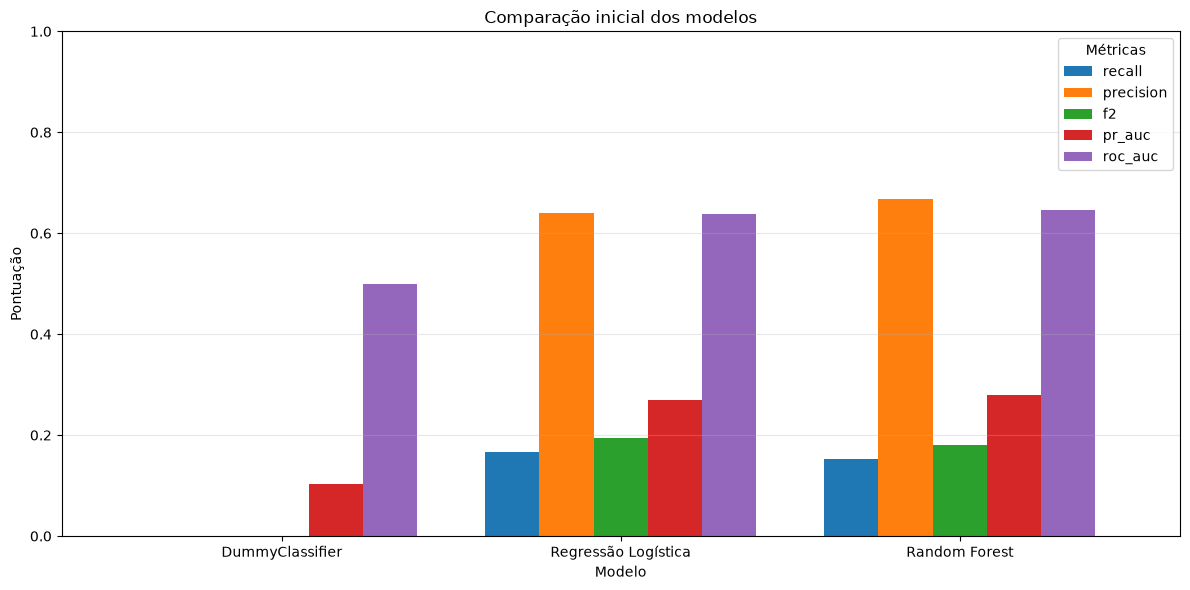

In [15]:
import matplotlib.pyplot as plt

metricas_principais = [
    "recall",
    "precision",
    "f2",
    "pr_auc",
    "roc_auc"
]

comparacao_inicial[metricas_principais].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Comparação inicial dos modelos")
plt.xlabel("Modelo")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Métricas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Tratamento do desbalanceamento das classes

### Regressão Logística com balanceamento

Considerando a baixa proporção de registros da
classe positiva e o baixo Recall dos modelos
iniciais, será investigado o balanceamento por
meio do parâmetro class_weight="balanced".

Essa estratégia atribui pesos inversamente
proporcionais à frequência das classes durante
o treinamento. Nisso serão mantidos os demais parâmetros, os mesmos folds e as mesmas métricas de avaliação.

O objetivo é melhorar o Recall e o F2-score,
analisando também o impacto sobre a Precision
e as demais métricas.

In [16]:
# Criar Regressão Logística com balanceamento
modelo_logistica_bal = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced",
    solver="lbfgs"
)

# Construir o pipeline completo
pipeline_logistica_bal = criar_pipeline(
    modelo_logistica_bal
)

# Executar a validação cruzada
resultados_logistica_bal = cross_validate(
    pipeline_logistica_bal,
    X_treino,
    y_treino,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

print("Validação cruzada da Regressão Logística balanceada concluída.")

Validação cruzada da Regressão Logística balanceada concluída.


In [ ]:
resumo_logistica_bal = pd.DataFrame({
    "Métrica": list(metricas.keys()),

    "Média": [
        resultados_logistica_bal[f"test_{metrica}"].mean()
        for metrica in metricas
    ],

    "Desvio-padrão": [
        resultados_logistica_bal[f"test_{metrica}"].std()
        for metrica in metricas
    ]
})

display(resumo_logistica_bal.round(4))


,Métrica,Média,Desvio-padrão
0,accuracy,0.7709,0.0078
1,recall,0.3839,0.0105
2,precision,0.1934,0.0081
3,f1,0.2572,0.0084
4,f2,0.3206,0.0087
5,pr_auc,0.2688,0.0069
6,roc_auc,0.6388,0.0077



Tempo médio de treinamento por fold: 1.225 segundos


O balanceamento aumentou consideravelmente o Recall e o F2-score da Regressão Logística. Entretanto, também houve uma redução significativa na Precision.

### Random Forest com balanceamento

O Random Forest será avaliado utilizando o parâmetro class_weight="balanced", atribuindo maior peso aos registros da classe minoritária. Serão mantidos os hiperparâmetros utilizados
no experimento anterior, permitindo avaliar o impacto específico do balanceamento.

A avaliação utilizará os mesmos cinco folds
estratificados e as mesmas métricas. O objetivo é verificar possíveis melhorias no Recall e no F2-score, considerando também
o impacto sobre a Precision e a capacidade discriminatória do modelo.

In [18]:
# Criar Random Forest com balanceamento
modelo_rf_bal = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Construir o pipeline completo
pipeline_rf_bal = criar_pipeline(modelo_rf_bal)

# Executar a validação cruzada
resultados_rf_bal = cross_validate(
    pipeline_rf_bal,
    X_treino,
    y_treino,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

print("Validação cruzada do Random Forest balanceado concluída.")

Validação cruzada do Random Forest balanceado concluída.


In [ ]:
resumo_rf_bal = pd.DataFrame({
    "Métrica": list(metricas.keys()),

    "Média": [
        resultados_rf_bal[f"test_{metrica}"].mean()
        for metrica in metricas
    ],

    "Desvio-padrão": [
        resultados_rf_bal[f"test_{metrica}"].std()
        for metrica in metricas
    ]
})

display(resumo_rf_bal.round(4))


,Métrica,Média,Desvio-padrão
0,accuracy,0.7991,0.0096
1,recall,0.3501,0.0150
2,precision,0.2133,0.0095
3,f1,0.2647,0.0067
4,f2,0.3099,0.0086
5,pr_auc,0.2742,0.0029
6,roc_auc,0.6437,0.0043



Tempo médio de treinamento por fold: 5.1535 segundos


O balanceamento melhorou a identificação dos casos positivos, mas reduziu a Precision. Assim como na Regressão Logística, não teve uma melhora na capacidade discriminatória medida pelo Average Precision e ROC-AUC.

In [ ]:
## Comparação dos modelos com e sem balanceamento

Foram realizados cinco experimentos utilizando
validação cruzada estratificada com cinco folds.

O balanceamento por pesos aumentou o Recall e
o F2-score dos classificadores, acompanhado de
uma redução na Precision e na acurácia.

A Regressão Logística balanceada apresentou
o maior Recall e F2-score nesta etapa.

O Random Forest sem balanceamento apresentou
os maiores valores de Average Precision e ROC-AUC.

In [20]:
# Consolidar todos os experimentos
resultados_completos = {
    "DummyClassifier": resultados_dummy,
    "Regressão Logística": resultados_logistica,
    "Random Forest": resultados_rf,
    "Logística balanceada": resultados_logistica_bal,
    "Random Forest balanceado": resultados_rf_bal
}

comparacao_completa = pd.DataFrame({
    nome: {
        metrica: resultado[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for nome, resultado in resultados_completos.items()
}).T

comparacao_completa.index.name = "Modelo"

# Ordenar pelo F2-score
comparacao_completa = comparacao_completa.sort_values(
    by="f2",
    ascending=False
)

display(comparacao_completa.round(4))

,accuracy,recall,precision,f1,f2,pr_auc,roc_auc
Modelo,,,,,,,
Logística balanceada,0.7709,0.3839,0.1934,0.2572,0.3206,0.2688,0.6388
Random Forest balanceado,0.7991,0.3501,0.2133,0.2647,0.3099,0.2742,0.6437
Regressão Logística,0.9042,0.1661,0.6396,0.2637,0.1950,0.2694,0.6383
Random Forest,0.9047,0.1531,0.6672,0.2490,0.1810,0.2786,0.6454
DummyClassifier,0.8968,0.0000,0.0000,0.0000,0.0000,0.1032,0.5000


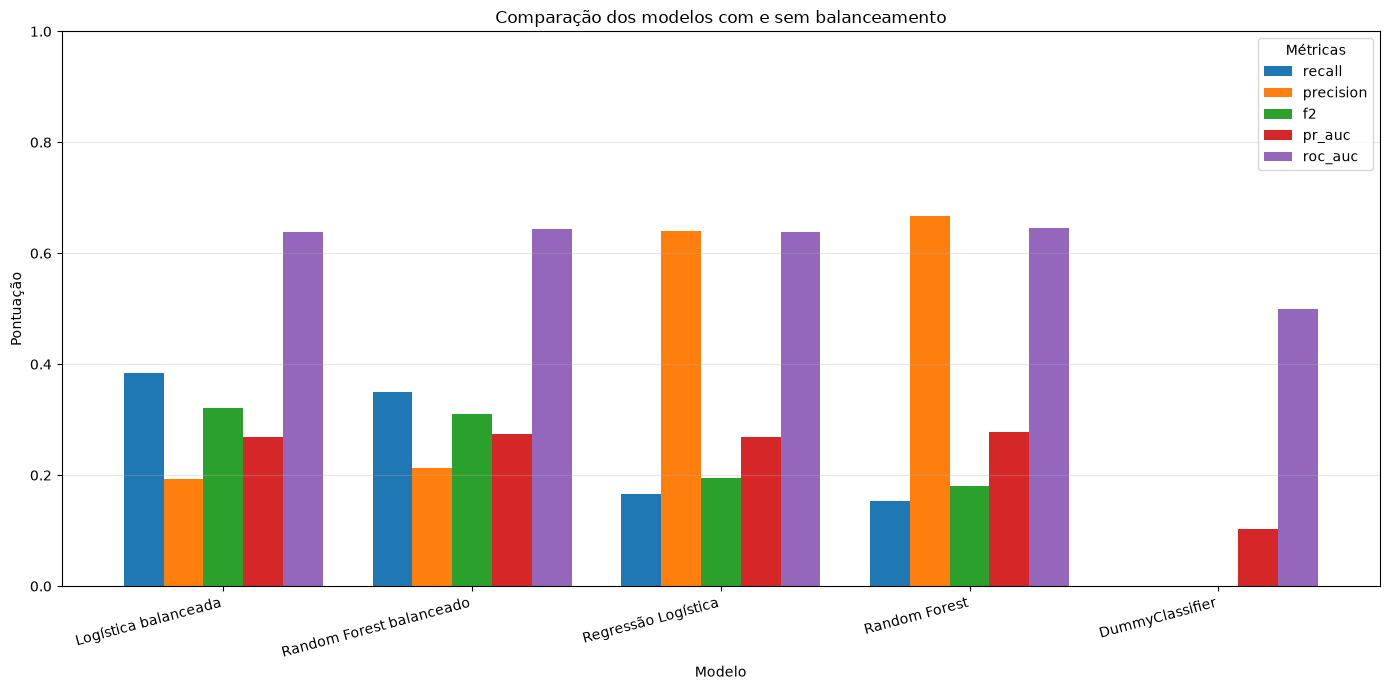

In [21]:
comparacao_completa[
    ["recall", "precision", "f2", "pr_auc", "roc_auc"]
].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Comparação dos modelos com e sem balanceamento")
plt.xlabel("Modelo")
plt.ylabel("Pontuação")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Métricas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Ajuste do limiar de classificação

Devido ao baixo Recall apresentado pelos
modelos no limiar padrão de 0,5, serão realizados 
diferentes limiares de classificação.

Serão utilizadas predições out-of-fold, obtidas
por validação cruzada estratificada exclusivamente
no conjunto de treinamento.

O F2-score será utilizado como critério de
otimização, priorizando o Recall sem desconsiderar
a Precision.


In [22]:
from sklearn.model_selection import cross_val_predict

# Modelos candidatos para ajuste do limiar
modelos_candidatos = {
    "Regressão Logística": pipeline_logistica,
    "Random Forest": pipeline_rf,
    "Logística balanceada": pipeline_logistica_bal,
    "Random Forest balanceado": pipeline_rf_bal
}

# Armazenar as probabilidades out-of-fold
probabilidades_oof = {}

for nome, pipeline in modelos_candidatos.items():

    print(f"Processando: {nome}", flush=True)

    probabilidades = cross_val_predict(
        pipeline,
        X_treino,
        y_treino,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )

    # Selecionar os scores da classe positiva
    probabilidades_oof[nome] = probabilidades[:, 1]

    print(
        "Predições geradas:",
        len(probabilidades_oof[nome])
    )

print("\nPredições out-of-fold concluídas!")

Processando: Regressão Logística
Predições geradas: 96624
Processando: Random Forest
Predições geradas: 96624
Processando: Logística balanceada
Predições geradas: 96624
Processando: Random Forest balanceado
Predições geradas: 96624

Predições out-of-fold concluídas!


## Comparação dos limiares de classificação

Serão avaliados diferentes limiares utilizando as predições out-of-fold dos quatro modelos candidatos. Os limiares serão investigados entre 0,05 e 0,95, com intervalos de 0,01.

Para cada combinação de modelo e limiar, serão calculadas as métricas de classificação, o F2-score será utilizado como critério principal de otimização do limiar, considerando também Recall, Precision e falsos positivos.

In [31]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix
)

# Definir os limiares que serão avaliados
limiares = np.arange(5, 96) / 100

resultados_limiares = []

# Avaliar cada modelo
for nome, probabilidades in probabilidades_oof.items():

    for limiar in limiares:

        # Converter scores em classes
        predicoes = (probabilidades >= limiar).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_treino,
            predicoes,
            labels=[0, 1]
        ).ravel()

        resultados_limiares.append({
            "Modelo": nome,
            "Limiar": limiar,

            "Accuracy": accuracy_score(
                y_treino, predicoes
            ),

            "Recall": recall_score(
                y_treino, predicoes, zero_division=0
            ),

            "Precision": precision_score(
                y_treino, predicoes, zero_division=0
            ),

            "F1": f1_score(
                y_treino, predicoes, zero_division=0
            ),

            "F2": fbeta_score(
                y_treino, predicoes,
                beta=2,
                zero_division=0
            ),

            "Falsos positivos": fp,
            "Falsos negativos": fn
        })

df_limiares = pd.DataFrame(resultados_limiares)

print("Combinações avaliadas:", len(df_limiares))
print("Avaliação dos limiares concluída!")

Combinações avaliadas: 455
Avaliação dos limiares concluída!


In [24]:
# Seleção do melhor limiar de cada modelo
# Selecionar a combinação com maior F2 de cada modelo
melhores_limiares = (
    df_limiares
    .sort_values(
        by=["F2", "Recall", "Precision"],
        ascending=False
    )
    .drop_duplicates(subset="Modelo")
    .reset_index(drop=True)
)

display(melhores_limiares.round(4))

,Modelo,Limiar,Accuracy,Recall,Precision,F1,F2,Falsos positivos,Falsos negativos
0,Random Forest balanceado,0.41,0.3229,0.8467,0.1168,0.2052,0.3762,63896,1529
1,Random Forest,0.08,0.4208,0.7602,0.1240,0.2132,0.3752,53573,2392
2,Logística balanceada,0.40,0.2857,0.8701,0.1136,0.2010,0.3731,67723,1296
3,Regressão Logística,0.07,0.2588,0.8925,0.1121,0.1991,0.3730,70548,1072


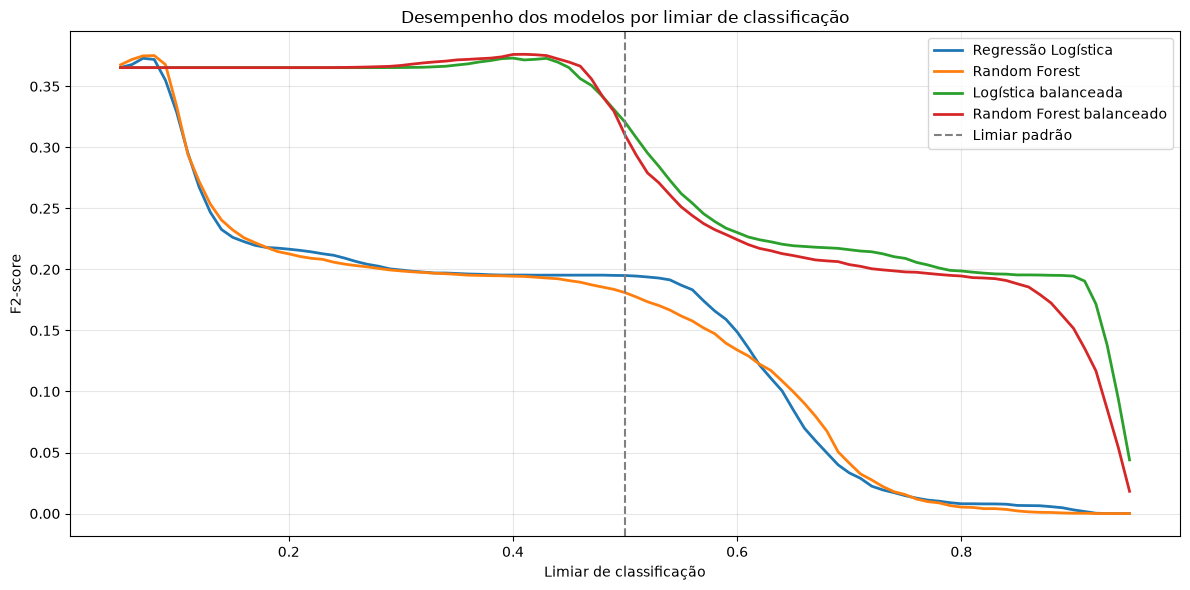

In [25]:
plt.figure(figsize=(12, 6))

for nome in probabilidades_oof:

    dados_modelo = df_limiares[
        df_limiares["Modelo"] == nome
    ]

    plt.plot(
        dados_modelo["Limiar"],
        dados_modelo["F2"],
        label=nome,
        linewidth=2
    )

plt.axvline(
    x=0.5,
    color="gray",
    linestyle="--",
    label="Limiar padrão"
)

plt.title("Desempenho dos modelos por limiar de classificação")
plt.xlabel("Limiar de classificação")
plt.ylabel("F2-score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

foi escolhido o intervalo de 0,05 a 0,95 com incrementos de 0,01 como uma estratégia inicial de busca.
O ajuste aumentou consideravelmente o Recall dos quatro modelos, mas mostra uma limitação: a quantidade elevada de falsos positivos.

## Análise do equilíbrio entre Recall e Precision

A maximização isolada do F2-score apresentou uma quantidade elevada de falsos positivos. Por esse motivo, serão investigados diferentes cenários de Recall mínimo, buscando identificar combinações de modelo e limiar que apresentem maior equilíbrio entre as métricas. A análise será realizada com as predições out-of-fold do conjunto de treino.


In [26]:
# Cenários de Recall mínimo
metas_recall = [0.50, 0.60, 0.70, 0.80]

resultados_equilibrio = []

for meta in metas_recall:

    candidatos = df_limiares[
        df_limiares["Recall"] >= meta
    ]

    if candidatos.empty:
        continue

    melhores = (
        candidatos
        .sort_values(
            by=["Precision", "F2", "Recall"],
            ascending=False
        )
        .drop_duplicates(subset="Modelo")
        .copy()
    )

    melhores["Recall mínimo"] = meta

    resultados_equilibrio.append(melhores)

df_equilibrio = pd.concat(
    resultados_equilibrio,
    ignore_index=True
)

colunas_exibicao = [
    "Recall mínimo",
    "Modelo",
    "Limiar",
    "Recall",
    "Precision",
    "F2",
    "Falsos positivos",
    "Falsos negativos"
]

display(df_equilibrio[colunas_exibicao].round(4))

,Recall mínimo,Modelo,Limiar,Recall,Precision,F2,Falsos positivos,Falsos negativos
0,0.5,Logística balanceada,0.47,0.5093,0.1562,0.3508,27436,4895
1,0.5,Random Forest balanceado,0.47,0.5451,0.1492,0.3561,31009,4538
2,0.5,Regressão Logística,0.09,0.5490,0.1471,0.3550,31751,4499
3,0.5,Random Forest,0.09,0.6183,0.1403,0.3678,37780,3807
4,0.6,Random Forest balanceado,0.46,0.6112,0.1409,0.3666,37170,3878
5,0.6,Random Forest,0.09,0.6183,0.1403,0.3678,37780,3807
6,0.6,Logística balanceada,0.45,0.6289,0.1365,0.3653,39686,3702
7,0.6,Regressão Logística,0.08,0.7431,0.1241,0.3720,52312,2563
8,0.7,Random Forest balanceado,0.43,0.7431,0.1259,0.3752,51465,2563
9,0.7,Logística balanceada,0.43,0.7443,0.1245,0.3729,52216,2551


## Otimização de hiperparâmetros do Random Forest

Após os experimentos iniciais de classificação,
balanceamento e ajuste de limiar, será realizada
uma busca por melhores hiperparâmetros.

Será utilizado RandomizedSearchCV com 20 configurações
e validação cruzada estratificada com cinco folds. A métrica utilizada para otimização será Average Precision, considerando o desbalanceamento da base e a avaliação independente do limiar de classificação.

Após a otimização, serão novamente avaliados
o Recall, a Precision, o F2-score e os limiares
de classificação.

In [27]:
from sklearn.model_selection import RandomizedSearchCV

# Definir o espaço de busca
parametros_rf = {
    "modelo__n_estimators": [50, 100, 200, 300],

    "modelo__max_depth": [5, 8, 12, 16, 20, None],

    "modelo__min_samples_split": [2, 5, 10, 20],

    "modelo__min_samples_leaf": [1, 3, 5, 10],

    "modelo__class_weight": [None, "balanced"],

    "modelo__max_features": ["sqrt", "log2", 0.5]
}

# Criar o pipeline para otimização
pipeline_rf_busca = criar_pipeline(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    )
)

# Configurar a busca aleatória
busca_rf = RandomizedSearchCV(
    estimator=pipeline_rf_busca,
    param_distributions=parametros_rf,
    n_iter=20,
    scoring=metricas,
    refit="pr_auc",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=True,
    error_score="raise"
)

print("Busca de hiperparâmetros configurada!")
print("Configurações:", busca_rf.n_iter)
print("Quantidade de folds:", cv.get_n_splits())

Busca de hiperparâmetros configurada!
Configurações: 20
Quantidade de folds: 5


In [28]:
# Executar a busca de hiperparâmetros
busca_rf.fit(X_treino, y_treino)

print("\nOtimização concluída!")

print("\nMelhores hiperparâmetros:")

for parametro, valor in busca_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print(
    "\nMelhor Average Precision:",
    round(busca_rf.best_score_, 4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END modelo__class_weight=None, modelo__max_depth=20, modelo__max_features=log2, modelo__min_samples_leaf=3, modelo__min_samples_split=20, modelo__n_estimators=50; total time=   3.5s
[CV] END modelo__class_weight=None, modelo__max_depth=20, modelo__max_features=log2, modelo__min_samples_leaf=3, modelo__min_samples_split=20, modelo__n_estimators=50; total time=   3.2s
[CV] END modelo__class_weight=None, modelo__max_depth=20, modelo__max_features=log2, modelo__min_samples_leaf=3, modelo__min_samples_split=20, modelo__n_estimators=50; total time=   3.4s
[CV] END modelo__class_weight=None, modelo__max_depth=20, modelo__max_features=log2, modelo__min_samples_leaf=3, modelo__min_samples_split=20, modelo__n_estimators=50; total time=   3.6s
[CV] END modelo__class_weight=None, modelo__max_depth=20, modelo__max_features=log2, modelo__min_samples_leaf=3, modelo__min_samples_split=20, modelo__n_estimators=50; total time=   3.5s
[CV

### Análise dos resultados da otimização

Serão analisados os melhores hiperparâmetros
encontrados pelo RandomizedSearchCV.

Também serão comparados os resultados de treinamento
e validação para investigar possíveis indícios
de overfitting.
A configuração otimizada será posteriormente
comparada com os modelos anteriores.


In [29]:
# Exibir todos os hiperparâmetros selecionados
print("Melhores hiperparâmetros:\n")

for parametro, valor in busca_rf.best_params_.items():
    print(f"{parametro}: {valor}")

# Recuperar os resultados da busca
df_busca = pd.DataFrame(busca_rf.cv_results_)

# Recuperar as métricas da melhor configuração
indice_melhor = busca_rf.best_index_

resumo_otimizado = pd.DataFrame({
    "Métrica": list(metricas.keys()),

    "Treinamento": [
        df_busca.loc[indice_melhor, f"mean_train_{m}"]
        for m in metricas
    ],

    "Validação": [
        df_busca.loc[indice_melhor, f"mean_test_{m}"]
        for m in metricas
    ],

    "Desvio-padrão": [
        df_busca.loc[indice_melhor, f"std_test_{m}"]
        for m in metricas
    ]
})

resumo_otimizado["Diferença"] = (
    resumo_otimizado["Treinamento"] -
    resumo_otimizado["Validação"]
)

display(resumo_otimizado.round(4))

Melhores hiperparâmetros:

modelo__n_estimators: 300
modelo__min_samples_split: 10
modelo__min_samples_leaf: 1
modelo__max_features: log2
modelo__max_depth: 12
modelo__class_weight: None


,Métrica,Treinamento,Validação,Desvio-padrão,Diferença
0,accuracy,0.9069,0.9048,0.0007,0.0021
1,recall,0.1598,0.1514,0.0033,0.0085
2,precision,0.7214,0.6734,0.0199,0.0480
3,f1,0.2617,0.2471,0.0049,0.0145
4,f2,0.1893,0.1791,0.0038,0.0102
5,pr_auc,0.3455,0.2802,0.0035,0.0652
6,roc_auc,0.6919,0.6456,0.0035,0.0463


## Avaliação do limiar do Random Forest otimizado

Após a otimização dos hiperparâmetros, serão
geradas predições out-of-fold utilizando a
melhor configuração encontrada.

O objetivo é investigar se o modelo otimizado
apresenta melhor equilíbrio entre Recall,
Precision e F2-score depois do ajuste do limiar.

In [30]:
from sklearn.base import clone

# Recuperar a melhor configuração encontrada
pipeline_rf_otimizado = clone(
    busca_rf.best_estimator_
)

# Gerar predições out-of-fold
probabilidades_rf_otimizado = cross_val_predict(
    pipeline_rf_otimizado,
    X_treino,
    y_treino,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Adicionar o modelo aos candidatos
modelos_candidatos["Random Forest otimizado"] = (
    pipeline_rf_otimizado
)

# Armazenar os scores
probabilidades_oof["Random Forest otimizado"] = (
    probabilidades_rf_otimizado
)

print("Predições out-of-fold concluídas!")
print("Modelo: Random Forest otimizado")
print("Predições geradas:", len(probabilidades_rf_otimizado))

Predições out-of-fold concluídas!
Modelo: Random Forest otimizado
Predições geradas: 96624


In [49]:
# Recalcular os limiares de todos os modelos candidatos
# Incluindo o Random Forest otimizado

limiares = np.arange(5, 96) / 100

resultados_limiares = []

for nome, scores in probabilidades_oof.items():

    for limiar in limiares:

        predicoes = (scores >= limiar).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_treino,
            predicoes,
            labels=[0, 1]
        ).ravel()

        resultados_limiares.append({
            "Modelo": nome,
            "Limiar": limiar,
            "Accuracy": accuracy_score(
                y_treino, predicoes
            ),
            "Recall": recall_score(
                y_treino, predicoes,
                zero_division=0
            ),
            "Precision": precision_score(
                y_treino, predicoes,
                zero_division=0
            ),
            "F1": f1_score(
                y_treino, predicoes,
                zero_division=0
            ),
            "F2": fbeta_score(
                y_treino, predicoes,
                beta=2,
                zero_division=0
            ),
            "Falsos positivos": int(fp),
            "Falsos negativos": int(fn)
        })

df_limiares = pd.DataFrame(resultados_limiares)

print("Modelos avaliados:", len(probabilidades_oof))
print("Limiares por modelo:", len(limiares))
print("Combinações avaliadas:", len(df_limiares))

assert len(probabilidades_oof) == 5
assert len(df_limiares) == 455

print("Validação da comparação final: OK")

Modelos avaliados: 5
Limiares por modelo: 91
Combinações avaliadas: 455
Validação da comparação final: OK


## Comparação final após a otimização

Após a busca de hiperparâmetros do Random Forest,
serão comparados novamente os limiares de classificação.

O modelo otimizado será avaliado juntamente com os quatro modelos anteriores, considerando Recall, Precision, F2-score,
quantidade de falsos positivos e custo computacional.

In [32]:
melhores_limiares_final = (
    df_limiares
    .sort_values(
        by=["F2", "Recall", "Precision"],
        ascending=False
    )
    .drop_duplicates(subset="Modelo")
    .reset_index(drop=True)
)

display(melhores_limiares_final.round(4))

,Modelo,Limiar,Accuracy,Recall,Precision,F1,F2,Falsos positivos,Falsos negativos
0,Random Forest otimizado,0.08,0.4267,0.7591,0.1250,0.2147,0.3769,52992,2403
1,Random Forest balanceado,0.41,0.3229,0.8467,0.1168,0.2052,0.3762,63896,1529
2,Random Forest,0.08,0.4208,0.7602,0.1240,0.2132,0.3752,53573,2392
3,Logística balanceada,0.40,0.2857,0.8701,0.1136,0.2010,0.3731,67723,1296
4,Regressão Logística,0.07,0.2588,0.8925,0.1121,0.1991,0.3730,70548,1072


In [33]:
comparacao_final = (
    df_limiares[df_limiares["Recall"] >= 0.70]
    .sort_values(
        by=["Precision", "F2", "Recall"],
        ascending=False
    )
    .drop_duplicates(subset="Modelo")
    .reset_index(drop=True)
)

display(comparacao_final.round(4))

,Modelo,Limiar,Accuracy,Recall,Precision,F1,F2,Falsos positivos,Falsos negativos
0,Random Forest balanceado,0.43,0.4408,0.7431,0.1259,0.2153,0.3752,51465,2563
1,Random Forest otimizado,0.08,0.4267,0.7591,0.1250,0.2147,0.3769,52992,2403
2,Logística balanceada,0.43,0.4332,0.7443,0.1245,0.2133,0.3729,52216,2551
3,Regressão Logística,0.08,0.4321,0.7431,0.1241,0.2127,0.3720,52312,2563
4,Random Forest,0.08,0.4208,0.7602,0.1240,0.2132,0.3752,53573,2392


## Seleção definitiva do modelo

Após a realização dos experimentos de classificação,
balanceamento, ajuste de limiares e otimização de
hiperparâmetros, foi selecionado o Random Forest
balanceado com 100 árvores e limiar de 0,43.

A otimização com RandomizedSearchCV avaliou 20 configurações utilizando cinco folds, totalizando 100 treinamentos durante a busca. O Random Forest otimizado apresentou Average Precision de 0,2802 e F2-score de 0,3769.

Entretanto, considerando o cenário experimental
de Recall mínimo de 70%, optou-se pelo Random
Forest balanceado, que apresentou maior Precision,
menor quantidade de falsos positivos em relação
ao modelo otimizado e menor complexidade
computacional em termos de quantidade de árvores.

Resultados out-of-fold do modelo selecionado:

- Recall: 0,7431.
- Precision: 0,1259.
- F2-score: 0,3752.
- Limiar: 0,43.

A diferença de desempenho entre as configurações foi pequena, não sendo possível estabelecer superioridade estatística, o modelo apresenta limitações como a baixa Precision.

In [34]:
from sklearn.base import clone

# Definir o modelo selecionado
nome_modelo_final = "Random Forest balanceado"

# Definir o limiar selecionado
limiar_final = 0.43

# Recuperar a configuração do pipeline selecionado
pipeline_final = clone(pipeline_rf_bal)

print("Modelo selecionado:", nome_modelo_final)
print("Limiar selecionado:", limiar_final)

# Recuperar os resultados da seleção
resultado_selecionado = df_limiares[
    (df_limiares["Modelo"] == nome_modelo_final) &
    np.isclose(df_limiares["Limiar"], limiar_final)
]

display(resultado_selecionado.round(4))

print("\nHiperparâmetros do classificador:")

for parametro, valor in (
    pipeline_final.named_steps["modelo"]
    .get_params()
    .items()
):
    print(f"{parametro}: {valor}")

Modelo selecionado: Random Forest balanceado
Limiar selecionado: 0.43


,Modelo,Limiar,Accuracy,Recall,Precision,F1,F2,Falsos positivos,Falsos negativos
311,Random Forest balanceado,0.43,0.4408,0.7431,0.1259,0.2153,0.3752,51465,2563



Hiperparâmetros do classificador:
bootstrap: True
ccp_alpha: 0.0
class_weight: balanced
criterion: gini
max_depth: 12
max_features: sqrt
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 5
min_samples_split: 10
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 100
n_jobs: -1
oob_score: False
random_state: 42
verbose: 0
warm_start: False


## Treinamento definitivo do modelo

Após a seleção do algoritmo, dos hiperparâmetros
e do limiar de classificação, o pipeline definitivo
será ajustado utilizando todos os registros do
conjunto de treinamento.

O modelo selecionado foi o Random Forest
com balanceamento de classes, 100 árvores,
profundidade máxima de 12 e limiar de 0,43.

O conjunto de teste permanece reservado
exclusivamente para a avaliação final.

Nenhum hiperparâmetro será alterado após
a avaliação final.

In [35]:
import time

# Registrar o início do treinamento
inicio = time.perf_counter()

# Treinar o pipeline definitivo
pipeline_final.fit(X_treino, y_treino)

# Calcular o tempo de treinamento
tempo_treinamento_final = (
    time.perf_counter() - inicio
)

print("Treinamento definitivo concluído!")

print("Modelo:", nome_modelo_final)

print("Registros utilizados:", len(X_treino))

print("Atributos de entrada:", X_treino.shape[1])

print("Classes reconhecidas:", pipeline_final.classes_)

print("Limiar selecionado:", limiar_final)

print(
    "Tempo de treinamento:",
    round(tempo_treinamento_final, 2),
    "segundos"
)

Treinamento definitivo concluído!
Modelo: Random Forest balanceado
Registros utilizados: 96624
Atributos de entrada: 10
Classes reconhecidas: [0 1]
Limiar selecionado: 0.43
Tempo de treinamento: 7.77 segundos


## Avaliação final do modelo

O modelo definitivo será avaliado utilizando
o conjunto de teste reservado, composto por
24.156 registros, será aplicado o limiar de classificação de 0,43, selecionado anteriormente por meio das predições out-of-fold.

Serão calculadas as métricas de classificação, a matriz de confusão e as curvas ROC e Precision-Recall.

Os resultados representam a avaliação final
do modelo em dados que não participaram do
ajuste ou da seleção dos modelos.

In [36]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report
)

# Obter os scores da classe positiva
probabilidades_teste = pipeline_final.predict_proba(
    X_teste
)[:, 1]

# Aplicar o limiar selecionado
predicoes_teste = (
    probabilidades_teste >= limiar_final
).astype(int)

print("Predições realizadas:", len(predicoes_teste))

print("\nDistribuição das classes previstas:")

display(
    pd.Series(predicoes_teste)
    .value_counts()
    .sort_index()
    .rename("Quantidade")
    .to_frame()
)

Predições realizadas: 24156

Distribuição das classes previstas:


,Quantidade
0,9550
1,14606


In [37]:
# Calcular as métricas no conjunto de teste
metricas_finais = {
    "accuracy": accuracy_score(
        y_teste, predicoes_teste
    ),

    "recall": recall_score(
        y_teste, predicoes_teste,
        zero_division=0
    ),

    "precision": precision_score(
        y_teste, predicoes_teste,
        zero_division=0
    ),

    "f1": f1_score(
        y_teste, predicoes_teste,
        zero_division=0
    ),

    "f2": fbeta_score(
        y_teste, predicoes_teste,
        beta=2,
        zero_division=0
    ),

    "pr_auc": average_precision_score(
        y_teste, probabilidades_teste
    ),

    "roc_auc": roc_auc_score(
        y_teste, probabilidades_teste
    )
}

resumo_final = pd.DataFrame({
    "Métrica": list(metricas_finais.keys()),
    "Resultado": list(metricas_finais.values())
})

display(resumo_final.round(4))

,Métrica,Resultado
0,accuracy,0.4449
1,recall,0.7398
2,precision,0.1263
3,f1,0.2158
4,f2,0.3753
5,pr_auc,0.2719
6,roc_auc,0.6407


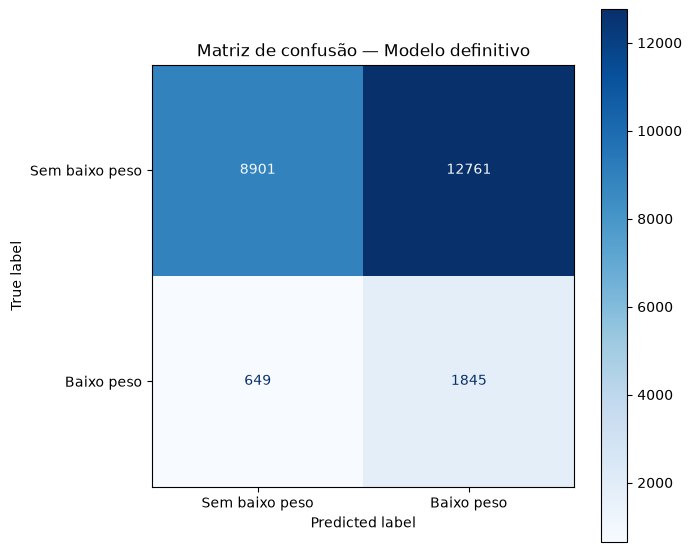

Verdadeiros negativos: 8901
Falsos positivos: 12761
Falsos negativos: 649
Verdadeiros positivos: 1845


In [38]:
# Matriz de confusão
from sklearn.metrics import ConfusionMatrixDisplay

# Calcular a matriz de confusão
matriz_final = confusion_matrix(
    y_teste,
    predicoes_teste,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_final.ravel()

# Exibir a matriz de confusão
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=["Sem baixo peso", "Baixo peso"]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de confusão — Modelo definitivo")
plt.tight_layout()
plt.show()

print("Verdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

## Curvas ROC e Precision-Recall

Serão apresentadas as curvas ROC e Precision-Recall
do modelo definitivo no conjunto de teste.

A curva ROC permite analisar a capacidade de
distinção entre as classes em diferentes limiares.A Precision-Recall permite avaliar o
equilíbrio entre Precision e Recall, sendo
especialmente relevante em bases desbalanceadas.

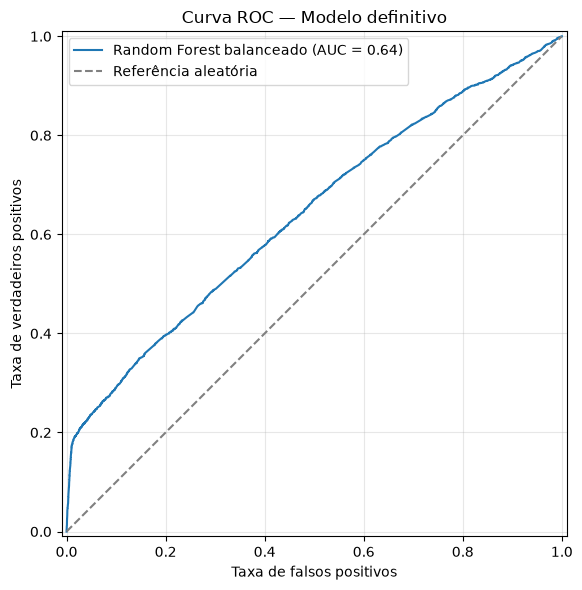

In [39]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_teste,
    probabilidades_teste,
    name="Random Forest balanceado",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Referência aleatória"
)

plt.title("Curva ROC — Modelo definitivo")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

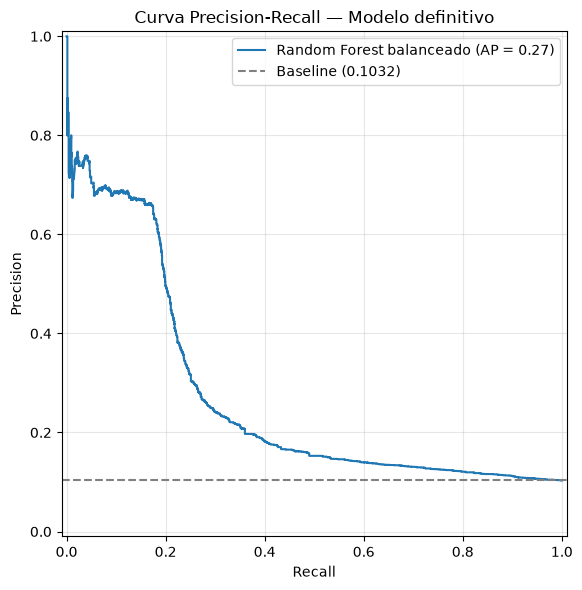

In [40]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_teste,
    probabilidades_teste,
    name="Random Forest balanceado",
    ax=ax
)

# Referência baseada na proporção da classe positiva
prevalencia_teste = y_teste.mean()

ax.axhline(
    y=prevalencia_teste,
    linestyle="--",
    color="gray",
    label=f"Baseline ({prevalencia_teste:.4f})"
)

plt.title("Curva Precision-Recall — Modelo definitivo")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Definição das faixas experimentais de score

Os scores produzidos pelo modelo serão organizados em três faixas experimentais: baixo, moderado e alto. O limite superior da faixa moderada corresponde ao limiar de classificação selecionado de 0,43.

O limite de 0,25 será investigado como uma proposta
de apresentação dos resultados.


In [41]:
# Recuperar os scores out-of-fold do modelo selecionado
scores_oof_final = probabilidades_oof[nome_modelo_final]

# Limites experimentais
limite_moderado = 0.25
limite_alto = limiar_final

# Classificar os scores em faixas
faixas_oof = pd.cut(
    scores_oof_final,
    bins=[0, limite_moderado, limite_alto, np.inf],
    labels=["Baixo", "Moderado", "Alto"],
    right=False,
    include_lowest=True
)

# Criar DataFrame para análise
analise_faixas = pd.DataFrame({
    "Faixa": faixas_oof,
    "Baixo_peso_real": y_treino.to_numpy()
})

# Consolidar os resultados
resumo_faixas = analise_faixas.groupby(
    "Faixa",
    observed=False
).agg(
    Registros=("Baixo_peso_real", "size"),
    Casos_positivos=("Baixo_peso_real", "sum"),
    Proporcao_positivos=("Baixo_peso_real", "mean")
)

resumo_faixas["Percentual_da_base"] = (
    resumo_faixas["Registros"] / len(analise_faixas) * 100
)

resumo_faixas["Proporcao_positivos"] *= 100

display(resumo_faixas.round(2))

,Registros,Casos_positivos,Proporcao_positivos,Percentual_da_base
Faixa,,,,
Baixo,101,3,2.97,0.10
Moderado,37646,2560,6.80,38.96
Alto,58877,7412,12.59,60.93


## AJustes das faixas experimentais de score

A primeira configuração apresentou baixa quantidade de registros na faixa inferior, serão analisados diferentes limites entre as faixas baixa e moderada, mantendo fixo o limiar
de classificação de 0,43. A análise utilizará exclusivamente as predições out-of-fold do conjunto de treinamento.


In [42]:
limites_candidatos = [0.30, 0.35, 0.38, 0.40]

resultados_faixas = []

for limite in limites_candidatos:

    faixas = pd.cut(
        scores_oof_final,
        bins=[0, limite, limiar_final, np.inf],
        labels=["Baixo", "Moderado", "Alto"],
        right=False,
        include_lowest=True
    )

    dados_faixas = pd.DataFrame({
        "Faixa": faixas,
        "Baixo_peso_real": y_treino.to_numpy()
    })

    resumo = dados_faixas.groupby(
        "Faixa",
        observed=False
    ).agg(
        Registros=("Baixo_peso_real", "size"),
        Casos_positivos=("Baixo_peso_real", "sum"),
        Proporcao_positivos=("Baixo_peso_real", "mean")
    ).reset_index()

    resumo["Limite inferior"] = limite

    resumo["Proporcao_positivos"] *= 100

    resumo["Percentual_da_base"] = (
        resumo["Registros"] / len(y_treino) * 100
    )

    resultados_faixas.append(resumo)

comparacao_faixas = pd.concat(
    resultados_faixas,
    ignore_index=True
)

display(comparacao_faixas[
    [
        "Limite inferior",
        "Faixa",
        "Registros",
        "Casos_positivos",
        "Proporcao_positivos",
        "Percentual_da_base"
    ]
].round(2))

,Limite inferior,Faixa,Registros,Casos_positivos,Proporcao_positivos,Percentual_da_base
0,0.30,Baixo,1555,66,4.24,1.61
1,0.30,Moderado,36192,2497,6.90,37.46
2,0.30,Alto,58877,7412,12.59,60.93
3,0.35,Baixo,7412,378,5.10,7.67
4,0.35,Moderado,30335,2185,7.20,31.39
5,0.35,Alto,58877,7412,12.59,60.93
6,0.38,Baixo,12550,724,5.77,12.99
7,0.38,Moderado,25197,1839,7.30,26.08
8,0.38,Alto,58877,7412,12.59,60.93
9,0.40,Baixo,19047,1138,5.97,19.71


O limite de 0,40 apresenta a distribuição mais equilibrada entre as faixas baixa e moderada dentre as configurações investigadas.

## Seleção das faixas experimentais de score

Após a investigação dos limites inferiores de
0,25, 0,30, 0,35, 0,38 e 0,40, foi selecionado
o limite de 0,40 entre as faixas baixa e moderada.

As faixas selecionadas foram:

- Baixo: score inferior a 0,40.
- Moderado: score maior ou igual a 0,40
  e inferior a 0,43.
- Alto: score maior ou igual a 0,43.

A escolha considerou o equilíbrio na distribuição dos registros entre as faixas baixa e moderada e a progressão da frequência observada de casos positivos, o limiar de classificação de 0,43 foi preservado. 

In [43]:
# Definir os limites selecionados
limite_moderado = 0.40
limite_alto = limiar_final

# Função para classificação experimental do score
def classificar_faixa(score):

    if not np.isfinite(score) or not 0 <= score <= 1:
        raise ValueError("Score inválido.")

    if score < limite_moderado:
        return "Baixo"

    elif score < limite_alto:
        return "Moderado"

    else:
        return "Alto"


# Testar utilizando scores fictícios
scores_exemplo = [
    0.00, 0.25, 0.39, 0.40,
    0.42, 0.43, 0.70, 1.00
]

teste_faixas = pd.DataFrame({
    "Score": scores_exemplo,
    "Faixa": [
        classificar_faixa(score)
        for score in scores_exemplo
    ]
})

display(teste_faixas)

# Validar os limites
assert classificar_faixa(0.39) == "Baixo"
assert classificar_faixa(0.40) == "Moderado"
assert classificar_faixa(0.42) == "Moderado"
assert classificar_faixa(0.43) == "Alto"

print("Validação das faixas: OK")

,Score,Faixa
0,0.00,Baixo
1,0.25,Baixo
2,0.39,Baixo
3,0.40,Moderado
4,0.42,Moderado
5,0.43,Alto
6,0.70,Alto
7,1.00,Alto


Validação das faixas: OK


## Exportação do modelo definitivo

O pipeline treinado será exportado utilizando
a biblioteca Joblib. O artefato incluirá todas as etapas de limpeza, pré-processamento e classificação.

A exportação permitirá a reutilização do modelo pela API sem necessidade de novo treinamento, o limiar de classificação e as faixas de score serão registrados separadamente nos metadados.


In [44]:
import joblib

# Definir o diretório de exportação
pasta_modelos = raiz / "ml" / "artifacts"

# Criar o diretório, caso não exista
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Definir o arquivo do modelo
caminho_modelo = pasta_modelos / "modelo_sinasc.joblib"

# Exportar o pipeline treinado
joblib.dump(
    pipeline_final,
    caminho_modelo,
    compress=3
)

print("Modelo exportado com sucesso!")

print("Arquivo:", caminho_modelo.name)

print("Diretório:", caminho_modelo.relative_to(raiz))

print(
    "Tamanho do arquivo:",
    round(caminho_modelo.stat().st_size / (1024 ** 2), 2),
    "MB"
)

Modelo exportado com sucesso!
Arquivo: modelo_sinasc.joblib
Diretório: ml\artifacts\modelo_sinasc.joblib
Tamanho do arquivo: 2.19 MB


## Validação do modelo exportado

O pipeline exportado será carregado utilizando joblib.load para verificar a integridade do artefato. Os scores produzidos pelo modelo carregado serão comparados com os scores do modelo original, também será verificada a consistência das classes
previstas utilizando o limiar de 0,43.

O objetivo é garantir a consistência da exportação
antes da integração com a API.

In [45]:
# Carregar o modelo exportado
modelo_carregado = joblib.load(caminho_modelo)

print("Modelo carregado com sucesso!")

# Gerar scores com o modelo carregado
scores_carregados = modelo_carregado.predict_proba(
    X_teste
)[:, 1]

# Aplicar o limiar selecionado
predicoes_carregadas = (
    scores_carregados >= limiar_final
).astype(int)

# Comparar com os resultados originais
scores_iguais = np.allclose(
    probabilidades_teste,
    scores_carregados,
    rtol=0,
    atol=1e-12
)

predicoes_iguais = np.array_equal(
    predicoes_teste,
    predicoes_carregadas
)

# Calcular a maior diferença entre os scores
diferenca_maxima = np.max(
    np.abs(
        probabilidades_teste - scores_carregados
    )
)

print("Predições realizadas:", len(predicoes_carregadas))
print("Scores equivalentes:", scores_iguais)
print("Predições idênticas:", predicoes_iguais)
print("Diferença máxima:", diferenca_maxima)

# Validar automaticamente os resultados
assert scores_iguais
assert predicoes_iguais

print("\nValidação do modelo exportado: OK")

Modelo carregado com sucesso!
Predições realizadas: 24156
Scores equivalentes: True
Predições idênticas: True
Diferença máxima: 3.3306690738754696e-16

Validação do modelo exportado: OK


## Exportação dos metadados do modelo

Os metadados serão armazenados em formato JSON
para facilitar a integração com o serviço de IA.

O arquivo incluirá:

- Identificação e versão do modelo.
- Informações sobre a base de dados.
- Atributos de entrada.
- Hiperparâmetros selecionados.
- Métricas da avaliação final.
- Matriz de confusão.
- Limiar de classificação.
- Faixas experimentais de score.
- Versões das bibliotecas.
- Limitações de utilização.

O objetivo é garantir a rastreabilidade,
a reprodutibilidade e a integração do modelo.

In [46]:
import json
import platform
import sklearn
import scipy
from datetime import datetime, timezone

# Construir os metadados
metadados = {
    "nome": "SINASC - Risco de baixo peso ao nascer",
    "versao": "1.0.0",
    "data_exportacao": datetime.now(timezone.utc).isoformat(),
    "algoritmo": nome_modelo_final,
    "arquivo_modelo": caminho_modelo.name,

    "dados": {
        "fonte": "SINASC - Município de São Paulo",
        "ano": 2024,
        "arquivo": "DNRE2024.csv",
        "registros_originais": int(len(df)),
        "duplicacoes_removidas": 5,
        "registros_validos": int(len(X)),
        "registros_treinamento": int(len(X_treino)),
        "registros_teste": int(len(X_teste)),
        "random_state": 42
    },

    "entrada": {
        "quantidade_atributos": int(X.shape[1]),
        "atributos": X.columns.tolist()
    },

    "variavel_alvo": {
        "nome": "baixo_peso",
        "classe_0": "Sem baixo peso",
        "classe_1": "Baixo peso",
        "criterio": "Peso ao nascer inferior a 2500 gramas"
    },

    "hiperparametros": (
        pipeline_final.named_steps["modelo"].get_params()
    ),

    "classificacao": {
        "classe_positiva": 1,
        "threshold": float(limiar_final),
        "score_calibrado": False,

        "faixas": {
            "baixo": {
                "min": 0.0,
                "max": 0.40,
                "max_inclusivo": False
            },
            "moderado": {
                "min": 0.40,
                "max": 0.43,
                "max_inclusivo": False
            },
            "alto": {
                "min": 0.43,
                "max": 1.0,
                "max_inclusivo": True
            }
        }
    },

    "metricas_teste": {
        nome: float(valor)
        for nome, valor in metricas_finais.items()
    },

    "matriz_confusao": {
        "verdadeiros_negativos": int(matriz_final[0, 0]),
        "falsos_positivos": int(matriz_final[0, 1]),
        "falsos_negativos": int(matriz_final[1, 0]),
        "verdadeiros_positivos": int(matriz_final[1, 1])
    },

    "dependencias": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "joblib": joblib.__version__
    },

    "limitacoes": [
        "Modelo exclusivamente academico e experimental.",
        "Nao validado para utilizacao clinica.",
        "Baixa precision e elevada quantidade de falsos positivos.",
        "Scores nao calibrados como probabilidades reais.",
        "Faixas de score sem validacao clinica.",
        "Base restrita ao municipio de Sao Paulo em 2024.",
        "Ausencia de validacao externa."
    ]
}

# Definir o caminho do arquivo JSON
caminho_metadados = pasta_modelos / "metadata.json"

# Exportar os metadados
with open(caminho_metadados, "w", encoding="utf-8") as arquivo:
    json.dump(
        metadados,
        arquivo,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print("Metadados exportados com sucesso!")
print("Arquivo:", caminho_metadados.name)
print("Diretório:", caminho_metadados.relative_to(raiz))

print("\nVersões das dependências:")

for biblioteca, versao in metadados["dependencias"].items():
    print(f"{biblioteca}: {versao}")

Metadados exportados com sucesso!
Arquivo: metadata.json
Diretório: ml\artifacts\metadata.json

Versões das dependências:
python: 3.11.9
scikit-learn: 1.9.1
pandas: 3.1.1
numpy: 2.4.6
scipy: 1.17.1
joblib: 1.6.0


## Contrato de entrada do modelo

O contrato de entrada estabelece os atributos, tipos e valores aceitos pelo pipeline treinado.
A API deverá fornecer os dez atributos originais, sem realizar previamente a codificação categórica, imputação ou padronização.

Essas transformações serão realizadas automaticamente pelo pipeline, o contrato será disponibilizado em formato JSON
para auxiliar a integração entre os componentes
do sistema.

In [48]:
# Definir o contrato de entrada
contrato_entrada = {
    "versao": "1.0.0",

    "atributos": {
        "FxEtPartur": {
            "tipo": "string",
            "descricao": "Faixa etaria materna",
            "valores_aceitos": [
                "10-14", "15-19", "20-24",
                "25-29", "30-34", "35-39",
                "40-44", "45-49", ">=50"
            ]
        },

        "ESTCIVMAE": {
            "tipo": "integer",
            "descricao": "Estado civil da mae",
            "valores_aceitos": [1, 2, 3, 4, 5]
        },

        "ESCMAE2010": {
            "tipo": "integer",
            "descricao": "Escolaridade materna",
            "valores_aceitos": [0, 1, 2, 3, 4, 5]
        },

        "GRAVIDEZ": {
            "tipo": "integer",
            "descricao": "Tipo de gravidez",
            "valores_aceitos": [1, 2, 3]
        },

        "QTDGESTANT": {
            "tipo": "integer",
            "descricao": "Gestacoes anteriores",
            "minimo": 0
        },

        "QTDPARTNOR": {
            "tipo": "integer",
            "descricao": "Partos normais anteriores",
            "minimo": 0
        },

        "QTDPARTCES": {
            "tipo": "integer",
            "descricao": "Partos cesareos anteriores",
            "minimo": 0
        },

        "QTDFILVIVO": {
            "tipo": "integer",
            "descricao": "Filhos vivos",
            "minimo": 0
        },

        "QTDFILMORT": {
            "tipo": "integer",
            "descricao": "Perdas fetais e abortos",
            "minimo": 0
        },

        "MESPRENAT": {
            "tipo": "integer",
            "descricao": "Mes de inicio do pre-natal",
            "minimo": 1,
            "maximo": 9
        }
    },

    "campos_obrigatorios": X.columns.tolist(),

    "aceita_valores_nulos": True,

    "permite_campos_extras": False,

    "observacoes": [
        "Todos os dez campos devem estar presentes.",
        "Valores desconhecidos podem ser enviados como null.",
        "Nao enviar atributos derivados.",
        "Nao realizar one-hot encoding externamente.",
        "O pipeline realiza o pre-processamento.",
        "Utilizacao exclusivamente academica."
    ]
}

# Identificar a finalidade do contrato
contrato_entrada["escopo"] = "Entrada interna do pipeline de IA"

# Códigos categóricos tratados como ignorados
for coluna in ["ESTCIVMAE", "ESCMAE2010", "GRAVIDEZ"]:
    contrato_entrada["atributos"][coluna]["codigos_ignorados"] = [9]

# Tratamento da faixa etária
contrato_entrada["atributos"]["FxEtPartur"]["codigos_ignorados"] = [
    "Ign"
]

# Tratamento do mês de início do pré-natal
contrato_entrada["atributos"]["MESPRENAT"]["codigos_ignorados"] = [
    99
]

# Documentar as regras externas ao pipeline
contrato_entrada["validacao_api"] = {
    "limite_contagens_obstetricas": {
        "minimo": 0,
        "maximo": 15
    },

    "responsabilidade": (
        "Validacao das requisicoes pelo servico de IA."
    ),

    "pendencias_alinhamento": [
        "Aceitacao de contagens obstetricas nulas.",
        "Aceitacao de MESPRENAT igual a 99.",
        "Aceitacao de Ign como faixa etaria.",
        "Validacao de consistencia entre partos e gestacoes.",
        "Tratamento de campos vazios ou omitidos."
    ]
}

contrato_entrada["observacoes"].extend([
    "Codigos ignorados sao tratados como ausentes pelo pipeline.",
    "MESPRENAT igual a 9 representa o nono mes.",
    "As regras da API podem ser mais restritivas que as do pipeline.",
    "O limite de 15 da API nao foi aplicado aos dados historicos de treinamento.",
    "O contrato interno nao substitui o contrato publico da API."
])

# Validar a correspondência com os atributos do modelo
assert set(contrato_entrada["atributos"]) == set(X.columns)

# Definir o caminho do contrato
caminho_contrato = pasta_modelos / "input_schema.json"

# Exportar o contrato
with open(caminho_contrato, "w", encoding="utf-8") as arquivo:
    json.dump(
        contrato_entrada,
        arquivo,
        ensure_ascii=False,
        indent=4
    )

print("Contrato de entrada exportado com sucesso!")
print("Arquivo:", caminho_contrato.name)
print("Diretório:", caminho_contrato.relative_to(raiz))
print("Quantidade de atributos:", len(contrato_entrada["atributos"]))
print("Validação dos atributos: OK")

Contrato de entrada exportado com sucesso!
Arquivo: input_schema.json
Diretório: ml\artifacts\input_schema.json
Quantidade de atributos: 10
Validação dos atributos: OK


In [50]:
print("Scores disponíveis:", len(scores_oof_final))
print("Registros de treinamento:", len(y_treino))
print("Limiar de classificação:", limiar_final)

Scores disponíveis: 96624
Registros de treinamento: 96624
Limiar de classificação: 0.43


## Revisão das faixas experimentais por percentis
Uma revisão realizada, identificou-se que a configuração anterior concentrava aproximadamente 61% dos registros na faixa ALTO.

Serão investigadas novas faixas utilizando percentis dos scores out-of-fold do conjunto de treinamento. Os cenários avaliados utilizarão o percentil 50 como limite entre BAIXO e MEDIO e os percentis 80, 85 e 90 como possíveis limites para ALTO.

O limiar de classificação de 0,43 será mantido
independentemente das faixas de apresentação.


In [51]:
# Percentis candidatos para a faixa ALTO
percentis_candidatos = [80, 85, 90]

# Limite entre BAIXO e MEDIO
limite_baixo_percentil = float(
    np.percentile(scores_oof_final, 50)
)

resultados_percentis = []

for percentil in percentis_candidatos:

    # Calcular o limite da faixa ALTO
    limite_alto_percentil = float(
        np.percentile(scores_oof_final, percentil)
    )

    # Classificar os scores
    faixas = pd.cut(
        scores_oof_final,
        bins=[
            0,
            limite_baixo_percentil,
            limite_alto_percentil,
            np.inf
        ],
        labels=["BAIXO", "MEDIO", "ALTO"],
        right=False,
        include_lowest=True
    )

    dados_percentis = pd.DataFrame({
        "Faixa": faixas,
        "Baixo_peso_real": y_treino.to_numpy()
    })

    # Consolidar os resultados
    resumo = dados_percentis.groupby(
        "Faixa",
        observed=False
    ).agg(
        Registros=("Baixo_peso_real", "size"),
        Casos_positivos=("Baixo_peso_real", "sum"),
        Proporcao_positivos=("Baixo_peso_real", "mean")
    ).reset_index()

    resumo["Percentil ALTO"] = percentil

    resumo["Limite BAIXO/MEDIO"] = (
        limite_baixo_percentil
    )

    resumo["Limite MEDIO/ALTO"] = (
        limite_alto_percentil
    )

    resumo["Percentual_da_base"] = (
        resumo["Registros"] / len(y_treino) * 100
    )

    resumo["Proporcao_positivos"] *= 100

    resumo["Percentual_casos_capturados"] = (
        resumo["Casos_positivos"] / y_treino.sum() * 100
    )

    resultados_percentis.append(resumo)

# Consolidar os três cenários
comparacao_percentis = pd.concat(
    resultados_percentis,
    ignore_index=True
)

display(
    comparacao_percentis[
        [
            "Percentil ALTO",
            "Limite BAIXO/MEDIO",
            "Limite MEDIO/ALTO",
            "Faixa",
            "Registros",
            "Casos_positivos",
            "Percentual_da_base",
            "Proporcao_positivos",
            "Percentual_casos_capturados"
        ]
    ].round(4)
)

print("Análise dos percentis concluída!")

,Percentil ALTO,Limite BAIXO/MEDIO,Limite MEDIO/ALTO,Faixa,Registros,Casos_positivos,Percentual_da_base,Proporcao_positivos,Percentual_casos_capturados
0,80,0.4495,0.4962,BAIXO,48261,3446,49.9472,7.1403,34.5464
1,80,0.4495,0.4962,MEDIO,29033,2738,30.0474,9.4306,27.4486
2,80,0.4495,0.4962,ALTO,19330,3791,20.0054,19.6120,38.0050
3,85,0.4495,0.5042,BAIXO,48261,3446,49.9472,7.1403,34.5464
4,85,0.4495,0.5042,MEDIO,33869,3243,35.0524,9.5751,32.5113
5,85,0.4495,0.5042,ALTO,14494,3286,15.0004,22.6715,32.9424
6,90,0.4495,0.5250,BAIXO,48261,3446,49.9472,7.1403,34.5464
7,90,0.4495,0.5250,MEDIO,38700,3795,40.0522,9.8062,38.0451
8,90,0.4495,0.5250,ALTO,9663,2734,10.0006,28.2935,27.4085


Análise dos percentis concluída!


## Seleção das faixas experimentais por percentis

Depois da revisão feita, foram investigadas configurações utilizando os percentis 80, 85 e 90 dos scores out-of-fold do conjunto de treinamento. Foi selecionada a configuração com percentil 50 para separar BAIXO e MEDIO e percentil 85 para separar MEDIO e ALTO.

A faixa ALTO passou a concentrar aproximadamente
15% dos registros, com frequência observada de
baixo peso de 22,67%, superior à prevalência
de 10,32% da base de treinamento.

A configuração selecionada concentra 32,94%
dos casos positivos na faixa ALTO. O limiar de classificação de 0,43 foi preservado para o cálculo das métricas do classificador.

As faixas de apresentação são independentes
da classificação binária. Os limites foram definidos exclusivamente com scores out-of-fold do conjunto de treinamento.

In [52]:
# Percentis selecionados
percentil_medio = 50
percentil_alto = 85

# Limites definitivos de apresentação
limite_medio_final = float(
    np.percentile(scores_oof_final, percentil_medio)
)

limite_alto_final = float(
    np.percentile(scores_oof_final, percentil_alto)
)

# Preservar o limiar do classificador
assert limiar_final == 0.43

# Validar os limites
assert 0 < limite_medio_final < limite_alto_final < 1

print("Limiar de classificação:", limiar_final)

print("\nLimites experimentais de apresentação:")
print("BAIXO/MEDIO:", repr(limite_medio_final))
print("MEDIO/ALTO:", repr(limite_alto_final))

# Recuperar os resultados do cenário selecionado
resumo_faixas_final = comparacao_percentis[
    comparacao_percentis["Percentil ALTO"] == 85
].copy()

display(resumo_faixas_final.round(4))

print("Novos limites definidos com sucesso!")

Limiar de classificação: 0.43

Limites experimentais de apresentação:
BAIXO/MEDIO: 0.4495018644184755
MEDIO/ALTO: 0.5042154221007533


,Faixa,Registros,Casos_positivos,Proporcao_positivos,Percentil ALTO,Limite BAIXO/MEDIO,Limite MEDIO/ALTO,Percentual_da_base,Percentual_casos_capturados
3,BAIXO,48261,3446,7.1403,85,0.4495,0.5042,49.9472,34.5464
4,MEDIO,33869,3243,9.5751,85,0.4495,0.5042,35.0524,32.5113
5,ALTO,14494,3286,22.6715,85,0.4495,0.5042,15.0004,32.9424


Novos limites definidos com sucesso!


## Validação das novas faixas experimentais

A função de classificação das faixas foi atualizada
para utilizar os limites definidos pelos percentis
50 e 85 dos scores out-of-fold.

As categorias foram padronizadas conforme o
contrato da API:

- BAIXO
- MEDIO
- ALTO

A classificação binária continua utilizando o limiar de 0,43, independentemente das faixas experimentais de apresentação, e os limites são utilizados com sua precisão original, evitando erros de arredondamento.

Esta configuração substitui as faixas
experimentais anteriores.

In [53]:
# Atualizar a função de classificação experimental
def classificar_faixa(score):

    if not np.isfinite(score) or not 0 <= score <= 1:
        raise ValueError("Score inválido.")

    if score < limite_medio_final:
        return "BAIXO"

    elif score < limite_alto_final:
        return "MEDIO"

    else:
        return "ALTO"


# Testar com scores fictícios e valores de fronteira
scores_exemplo = [
    0.00,
    0.339087,
    0.43,
    0.44,
    limite_medio_final,
    0.48,
    limite_alto_final,
    0.60,
    0.73,
    1.00
]

teste_novas_faixas = pd.DataFrame({
    "Score": scores_exemplo,

    "Classe prevista": [
        int(score >= limiar_final)
        for score in scores_exemplo
    ],

    "Faixa experimental": [
        classificar_faixa(score)
        for score in scores_exemplo
    ]
})

display(teste_novas_faixas.round(6))

# Validar os limites exatos
assert classificar_faixa(0.00) == "BAIXO"

assert classificar_faixa(
    np.nextafter(limite_medio_final, -np.inf)
) == "BAIXO"

assert classificar_faixa(
    limite_medio_final
) == "MEDIO"

assert classificar_faixa(
    np.nextafter(limite_alto_final, -np.inf)
) == "MEDIO"

assert classificar_faixa(
    limite_alto_final
) == "ALTO"

assert classificar_faixa(1.00) == "ALTO"

assert limiar_final == 0.43

print("Validação das novas faixas: OK")
print("Limiar de classificação preservado:", limiar_final)

,Score,Classe prevista,Faixa experimental
0,0.000000,0,BAIXO
1,0.339087,0,BAIXO
2,0.430000,1,BAIXO
3,0.440000,1,BAIXO
4,0.449502,1,MEDIO
5,0.480000,1,MEDIO
6,0.504215,1,ALTO
7,0.600000,1,ALTO
8,0.730000,1,ALTO
9,1.000000,1,ALTO


Validação das novas faixas: OK
Limiar de classificação preservado: 0.43


## Análise de sensibilidade a valores ausentes

Também foi identificado que a ausência do atributo GRAVIDEZ pode provocar um aumento significativo no score experimental.Para investigar esse comportamento, será utilizado um registro fictício como referência.

Cada atributo será substituído individualmente por um valor ausente, mantendo os demais atributos inalterados. Serão comparados os scores, as diferenças em relação ao registro original e as respectivas faixas experimentais.

O objetivo é identificar limitações do modelo
relacionadas à ausência de informações.

In [54]:
# Registro fictício de referência
dados_referencia = {
    "FxEtPartur": "25-29",
    "ESTCIVMAE": 2,
    "ESCMAE2010": 4,
    "GRAVIDEZ": 1,
    "QTDGESTANT": 2,
    "QTDPARTNOR": 1,
    "QTDPARTCES": 1,
    "QTDFILVIVO": 2,
    "QTDFILMORT": 0,
    "MESPRENAT": 3
}

# Converter para DataFrame
entrada_referencia = pd.DataFrame(
    [dados_referencia],
    columns=X.columns
)

# Calcular o score original
score_referencia = float(
    pipeline_final.predict_proba(
        entrada_referencia
    )[0, 1]
)

resultados_sensibilidade = []

# Testar a ausência de cada atributo
for atributo in dados_referencia:

    dados_alterados = dados_referencia.copy()

    # Substituir somente um atributo por valor ausente
    dados_alterados[atributo] = None

    entrada_alterada = pd.DataFrame(
        [dados_alterados],
        columns=X.columns
    )

    # Calcular o novo score
    score_alterado = float(
        pipeline_final.predict_proba(
            entrada_alterada
        )[0, 1]
    )

    resultados_sensibilidade.append({
        "Atributo ausente": atributo,
        "Score original": score_referencia,
        "Score alterado": score_alterado,
        "Variacao do score": (
            score_alterado - score_referencia
        ),
        "Faixa original": classificar_faixa(
            score_referencia
        ),
        "Faixa alterada": classificar_faixa(
            score_alterado
        )
    })

# Consolidar os resultados
df_sensibilidade = pd.DataFrame(
    resultados_sensibilidade
)

df_sensibilidade = df_sensibilidade.sort_values(
    by="Variacao do score",
    ascending=False
).reset_index(drop=True)

print("Score de referência:", round(score_referencia, 6))

print("Faixa de referência:", classificar_faixa(
    score_referencia
))

display(df_sensibilidade.round(6))

print("Análise de sensibilidade concluída!")

Score de referência: 0.339087
Faixa de referência: BAIXO


,Atributo ausente,Score original,Score alterado,Variacao do score,Faixa original,Faixa alterada
0,GRAVIDEZ,0.339087,0.732275,0.393188,BAIXO,ALTO
1,MESPRENAT,0.339087,0.525467,0.186380,BAIXO,ALTO
2,FxEtPartur,0.339087,0.384969,0.045882,BAIXO,BAIXO
3,ESTCIVMAE,0.339087,0.369606,0.030519,BAIXO,BAIXO
4,QTDFILVIVO,0.339087,0.356813,0.017725,BAIXO,BAIXO
5,QTDPARTCES,0.339087,0.342643,0.003556,BAIXO,BAIXO
6,QTDPARTNOR,0.339087,0.341849,0.002762,BAIXO,BAIXO
7,QTDFILMORT,0.339087,0.339087,0.000000,BAIXO,BAIXO
8,QTDGESTANT,0.339087,0.329086,-0.010001,BAIXO,BAIXO
9,ESCMAE2010,0.339087,0.324452,-0.014635,BAIXO,BAIXO


Análise de sensibilidade concluída!


## Investigação da ausência de atributos no treinamento

A análise de sensibilidade identificou alterações
relevantes no score experimental quando os
atributos GRAVIDEZ e MESPRENAT foram omitidos
individualmente em um registro fictício.

Para investigar possíveis associações aprendidaspelo modelo, será analisada a frequência de baixo peso entre registros com informações válidas
e informações ausentes nesses atributos. A análise utilizará exclusivamente o conjunto de treinamento.

In [55]:
from preprocessing import limpar_atributos

# Aplicar a mesma limpeza utilizada pelo pipeline
X_treino_limpo = limpar_atributos(X_treino)

atributos_investigados = [
    "GRAVIDEZ",
    "MESPRENAT"
]

resultados_ausencia = []

for atributo in atributos_investigados:

    # Identificar informações ausentes após a limpeza
    ausentes = X_treino_limpo[atributo].isna()

    dados_analise = pd.DataFrame({
        "Situacao": np.where(
            ausentes,
            "Ausente",
            "Informado"
        ),
        "Baixo_peso_real": y_treino.to_numpy()
    })

    resumo = dados_analise.groupby(
        "Situacao"
    ).agg(
        Registros=("Baixo_peso_real", "size"),
        Casos_positivos=("Baixo_peso_real", "sum"),
        Proporcao_positivos=("Baixo_peso_real", "mean")
    ).reset_index()

    resumo["Atributo"] = atributo

    resumo["Percentual_da_base"] = (
        resumo["Registros"] / len(y_treino) * 100
    )

    resumo["Proporcao_positivos"] *= 100

    resultados_ausencia.append(resumo)

df_analise_ausencia = pd.concat(
    resultados_ausencia,
    ignore_index=True
)

print("Prevalência geral no treinamento:",
      round(y_treino.mean() * 100, 4), "%")

display(
    df_analise_ausencia[
        [
            "Atributo",
            "Situacao",
            "Registros",
            "Casos_positivos",
            "Percentual_da_base",
            "Proporcao_positivos"
        ]
    ].round(4)
)

print("Investigação dos valores ausentes concluída!")


Prevalência geral no treinamento: 10.3235 %


,Atributo,Situacao,Registros,Casos_positivos,Percentual_da_base,Proporcao_positivos
0,GRAVIDEZ,Ausente,8,2,0.0083,25.0000
1,GRAVIDEZ,Informado,96616,9973,99.9917,10.3223
2,MESPRENAT,Ausente,811,225,0.8393,27.7435
3,MESPRENAT,Informado,95813,9750,99.1607,10.1761


Investigação dos valores ausentes concluída!


## Conclusão da análise de sensibilidade

A análise realizada com um registro fictício demonstrou sensibilidade do modelo à ausência dos atributos GRAVIDEZ e MESPRENAT.

A ausência de GRAVIDEZ alterou o score de
0,339087 para 0,732275.

A ausência de MESPRENAT alterou o score de
0,339087 para 0,525467.

Em ambos os casos, a faixa experimental
foi alterada de BAIXO para ALTO.

No conjunto de treinamento, foram identificados:

- GRAVIDEZ ausente: 8 registros, sendo
  2 positivos (25,00%).

- MESPRENAT ausente ou invalido: 811 registros,
  sendo 225 positivos (27,74%).

A baixa representatividade dos registros com GRAVIDEZ ausente pode contribuir para a instabilidade do modelo nessa condição.

In [56]:
# Remover o código Ign do contrato de entrada
contrato_entrada["atributos"]["FxEtPartur"].pop(
    "codigos_ignorados",
    None
)

# Garantir que Ign não esteja na lista de valores aceitos
contrato_entrada["atributos"]["FxEtPartur"][
    "valores_aceitos"
] = [
    valor
    for valor in contrato_entrada["atributos"][
        "FxEtPartur"
    ]["valores_aceitos"]
    if valor != "Ign"
]

# Documentar o tratamento esperado
contrato_entrada["atributos"]["FxEtPartur"][
    "tratamento_ausencia"
] = "Enviar null quando a informacao for desconhecida."

# Atualizar as pendências de alinhamento
pendencias = contrato_entrada[
    "validacao_api"
]["pendencias_alinhamento"]

contrato_entrada["validacao_api"][
    "pendencias_alinhamento"
] = [
    pendencia
    for pendencia in pendencias
    if "Ign como faixa etaria" not in pendencia
]

# Registrar a sensibilidade a valores ausentes
contrato_entrada["observacoes"].extend([
    "FxEtPartur desconhecido deve ser enviado como null.",
    "A ausencia de GRAVIDEZ pode alterar significativamente o score.",
    "A ausencia de MESPRENAT pode alterar significativamente o score.",
    "A ausencia de informacao nao implica maior risco clinico."
])

# Atualizar o arquivo JSON
with open(caminho_contrato, "w", encoding="utf-8") as arquivo:
    json.dump(
        contrato_entrada,
        arquivo,
        ensure_ascii=False,
        indent=4
    )

# Validar os atributos
assert len(contrato_entrada["atributos"]) == 10

assert "Ign" not in contrato_entrada[
    "atributos"
]["FxEtPartur"]["valores_aceitos"]

print("Contrato de entrada atualizado com sucesso!")
print("Arquivo:", caminho_contrato.name)
print("Quantidade de atributos:", len(
    contrato_entrada["atributos"]
))

print("\nContrato atualizado de FxEtPartur:")

print(json.dumps(
    contrato_entrada["atributos"]["FxEtPartur"],
    indent=4,
    ensure_ascii=False
))

Contrato de entrada atualizado com sucesso!
Arquivo: input_schema.json
Quantidade de atributos: 10

Contrato atualizado de FxEtPartur:
{
    "tipo": "string",
    "descricao": "Faixa etaria materna",
    "valores_aceitos": [
        "10-14",
        "15-19",
        "20-24",
        "25-29",
        "30-34",
        "35-39",
        "40-44",
        "45-49",
        ">=50"
    ],
    "tratamento_ausencia": "Enviar null quando a informacao for desconhecida."
}


## Atualização dos metadados após revisão do PR

As faixas experimentais passam a utilizar os percentis 50 e 85 dos scores out-of-fold. O limiar de classificação permanece em 0,43.

As categorias foram padronizadas como BAIXO, MEDIO e ALTO, conforme o contrato da API. Também foram documentadas as limitações relacionadas aos valores ausentes e à ausência
de calibração dos scores.

O pipeline treinado permanece inalterado.

In [57]:
# Atualizar os metadados da classificação
metadados["classificacao"] = {
    "classe_positiva": 1,
    "threshold": float(limiar_final),
    "score_calibrado": False,

    "tipo_score": "Score experimental nao calibrado",

    "metodo_definicao_faixas": {
        "metodo": "Percentis",
        "referencia": "Predicoes out-of-fold do treinamento",
        "percentil_baixo_medio": 50,
        "percentil_medio_alto": 85
    },

    "faixas_independentes_da_classe": True,

    "faixas": {
        "BAIXO": {
            "min": 0.0,
            "max": float(limite_medio_final),
            "max_inclusivo": False
        },

        "MEDIO": {
            "min": float(limite_medio_final),
            "max": float(limite_alto_final),
            "max_inclusivo": False
        },

        "ALTO": {
            "min": float(limite_alto_final),
            "max": 1.0,
            "max_inclusivo": True
        }
    }
}

# Registrar os resultados das novas faixas
metadados["avaliacao_faixas_oof"] = {}

for _, linha in resumo_faixas_final.iterrows():

    faixa = str(linha["Faixa"])

    metadados["avaliacao_faixas_oof"][faixa] = {
        "registros": int(linha["Registros"]),

        "casos_positivos": int(
            linha["Casos_positivos"]
        ),

        "percentual_da_base": float(
            linha["Percentual_da_base"]
        ),

        "proporcao_positivos_pct": float(
            linha["Proporcao_positivos"]
        ),

        "percentual_casos_capturados": float(
            linha["Percentual_casos_capturados"]
        )
    }

# Registrar a análise de sensibilidade
metadados["sensibilidade_ausencia"] = {
    "tipo_teste": "Registro ficticio",
    "score_referencia": float(score_referencia),

    "atributos": {
        str(linha["Atributo ausente"]): {
            "score_alterado": float(
                linha["Score alterado"]
            ),

            "variacao_score": float(
                linha["Variacao do score"]
            ),

            "faixa_alterada": str(
                linha["Faixa alterada"]
            )
        }

        for _, linha in df_sensibilidade.iterrows()
    }
}

# Acrescentar as novas limitações
novas_limitacoes = [
    "A ausencia de GRAVIDEZ pode aumentar significativamente o score.",

    "GRAVIDEZ ausente possui baixa representatividade no treinamento.",

    "A ausencia de MESPRENAT pode aumentar significativamente o score.",

    "A sensibilidade foi demonstrada em um registro ficticio e nao comprova comportamento universal.",

    "As faixas por percentis representam posicoes relativas na distribuicao de referencia.",

    "A distribuicao das faixas pode variar em novos dados.",

    "A faixa ALTO concentra aproximadamente 32,94% dos casos positivos nas predicoes out-of-fold.",

    "O recall do classificador nao equivale a proporcao de casos capturados pela faixa ALTO."
]

# Evitar duplicação das limitações
metadados["limitacoes"] = list(dict.fromkeys(
    metadados["limitacoes"] + novas_limitacoes
))

# Registrar a atualização dos metadados
metadados["data_atualizacao"] = (
    datetime.now(timezone.utc).isoformat()
)

# Validar antes de exportar
assert metadados["classificacao"]["threshold"] == 0.43

assert set(
    metadados["classificacao"]["faixas"]
) == {"BAIXO", "MEDIO", "ALTO"}

assert metadados["classificacao"]["score_calibrado"] is False

# Exportar os metadados atualizados
with open(caminho_metadados, "w", encoding="utf-8") as arquivo:
    json.dump(
        metadados,
        arquivo,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print("Metadados atualizados com sucesso!")

print("\nConfiguração atualizada:")

print(json.dumps(
    metadados["classificacao"],
    indent=4,
    ensure_ascii=False
))

print("\nValidação dos metadados: OK")

Metadados atualizados com sucesso!

Configuração atualizada:
{
    "classe_positiva": 1,
    "threshold": 0.43,
    "score_calibrado": false,
    "tipo_score": "Score experimental nao calibrado",
    "metodo_definicao_faixas": {
        "metodo": "Percentis",
        "referencia": "Predicoes out-of-fold do treinamento",
        "percentil_baixo_medio": 50,
        "percentil_medio_alto": 85
    },
    "faixas_independentes_da_classe": true,
    "faixas": {
        "BAIXO": {
            "min": 0.0,
            "max": 0.4495018644184755,
            "max_inclusivo": false
        },
        "MEDIO": {
            "min": 0.4495018644184755,
            "max": 0.5042154221007533,
            "max_inclusivo": false
        },
        "ALTO": {
            "min": 0.5042154221007533,
            "max": 1.0,
            "max_inclusivo": true
        }
    }
}

Validação dos metadados: OK


In [58]:
from importlib.metadata import version

# Registrar as versões das dependências adicionais
dependencias_adicionais = [
    "shap",
    "fastapi",
    "uvicorn",
    "pydantic"
]

for biblioteca in dependencias_adicionais:
    metadados["dependencias"][biblioteca] = version(
        biblioteca
    )

# Atualizar o arquivo de metadados
with open(caminho_metadados, "w", encoding="utf-8") as arquivo:
    json.dump(
        metadados,
        arquivo,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print("Dependências atualizadas nos metadados!\n")

for biblioteca, versao in metadados["dependencias"].items():
    print(f"{biblioteca}: {versao}")

Dependências atualizadas nos metadados!

python: 3.11.9
scikit-learn: 1.9.1
pandas: 3.1.1
numpy: 2.4.6
scipy: 1.17.1
joblib: 1.6.0
shap: 0.51.0
fastapi: 0.165.0
uvicorn: 0.54.0
pydantic: 2.14.4
